In [2]:
#importing necessary packages 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns


In [3]:
#loading in the data 
ridership_df = pd.read_csv("C:/Users/ilian/Downloads/SI_345/data/bus_ridership.csv")

#looking at the data 
ridership_df

,route_id,route_name,direction,date,time_period,day_of_week,riders,temperature_f,precipitation_inches,is_holiday,route_type,service_area
0,Route_12,Airport Express,Inbound,2023-07-21,Morning_Rush,Friday,531,63.5,0.00,False,Express,Suburban
1,Route_13,Harbor Line,Inbound,2023-09-12,Evening_Rush,Tuesday,1230,43.1,0.00,False,Rapid,Downtown
2,Route_1,Main Street Local,Outbound,2024-10-07,Night,Monday,208,42.2,0.00,False,Local,Downtown
3,Route_24,Waterfront Local,Inbound,2024-12-13,Midday,Friday,337,46.0,0.00,False,Local,Downtown
4,Route_20,Pine Street Local,Outbound,2024-10-06,Night,Sunday,75,38.1,0.00,False,Local,Downtown
...,...,...,...,...,...,...,...,...,...,...,...,...
146195,Route_9,North Local,Outbound,2024-07-05,Morning_Rush,Friday,398,58.6,0.10,False,Local,Suburban
146196,Route_10,South Express,Outbound,2024-08-22,Night,Thursday,123,77.1,0.62,False,Express,Downtown
146197,Route_12,Airport Express,Outbound,2024-06-02,Evening_Rush,Sunday,398,74.7,0.00,False,Express,Suburban
146198,Route_17,River Rapid,Outbound,2024-10-21,Morning_Rush,Monday,952,32.8,0.00,False,Rapid,Downtown


In [4]:
#looking at the data to see if there are null values
ridership_df.isna().value_counts()

#no null values 

#making the dates into datetime because i need it later 
ridership_df["date"] = pd.to_datetime(ridership_df["date"])

# Part 1: Distribution Visualizations

Create visualizations that show the distribution of ridership data:

Create a histogram showing the overall distribution of ridership across all observations. Include proper labels, title, and consider bin size carefully.

Create a kernel density estimate (KDE) plot comparing ridership distributions for different route types (Local, Express, Rapid). Use this to show how ridership patterns differ by route type.

Create a box plot showing ridership by time period (Morning Rush, Midday, Evening Rush, Night). Can you customize aspects of the box plot to highlight your story?

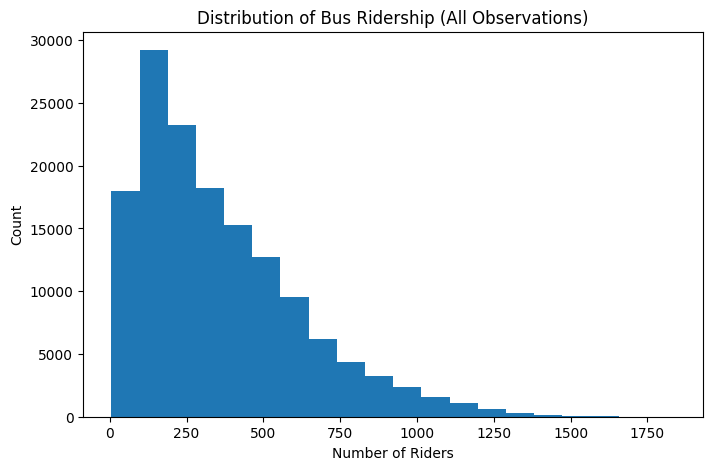

In [ ]:
#histogram
plt.figure(figsize=(8, 5))

plt.hist(ridership_df["riders"], bins=20)

plt.title("Distribution of Bus Ridership (All Observations)")
plt.xlabel("Number of Riders")
plt.ylabel("Count")
plt.show()

This histogram shows the distribution of riders across all observations. It shows that the majority of observations are between 0 and around 400 riders at a time. The distribution is right skewed and unimodal. 

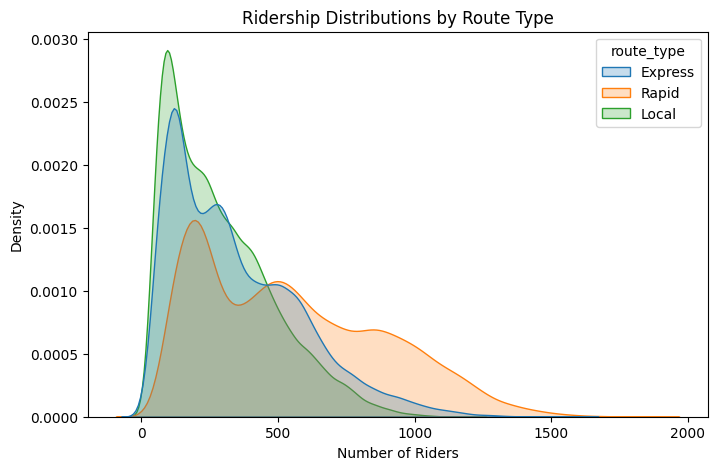

In [6]:
#KDE plot 
plt.figure(figsize=(8, 5))

# Only keep the three route types
route_types = ["Local", "Express", "Rapid"]
subset = ridership_df[ridership_df["route_type"].isin(route_types)]

sns.kdeplot(
    data=subset,
    x="riders",
    hue="route_type",
    common_norm=False,
    fill=True
)

plt.title("Ridership Distributions by Route Type")
plt.xlabel("Number of Riders")
plt.ylabel("Density")
plt.show()

This KDE plot shows the number of riders by route type in all of the observations. The density is highest for the local routes, which makes sense because more people are concentrated in their local area. The highest number of riders come from the rapid routes, but they are less dense, meaning less observations contain those mneasurements. 

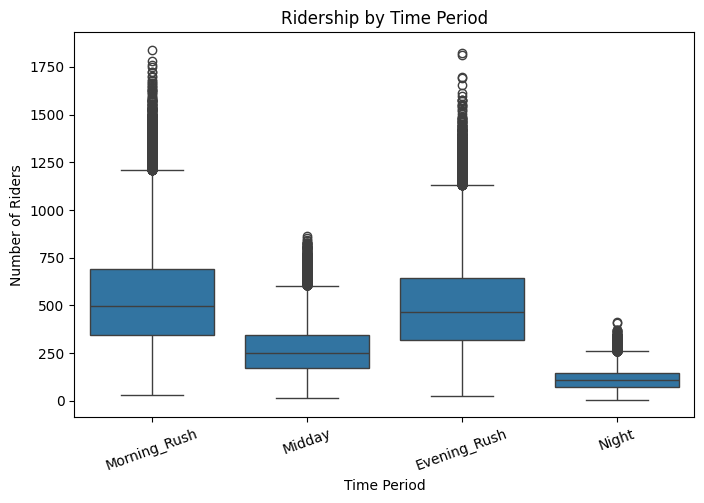

In [7]:
#box plot 
plt.figure(figsize=(8, 5))

# Ordering the time periods
time_order = ["Morning_Rush", "Midday", "Evening_Rush", "Night"]

sns.boxplot(
    data=ridership_df,
    x="time_period",
    y="riders",
    order=time_order
)

plt.title("Ridership by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Riders")
plt.xticks(rotation=20)
plt.show()

This grouped box plot shows the distribution of the number of riders organized by time period. The morning rush and evening rush have higher distributions, which makes sense because those are the rush times where most people are travelling to and from work.

# Part 2: Categorical Comparisons

Create visualizations that compare ridership across categories:

Create a bar plot showing total ridership by day of week. Order the days appropriately (Monday through Sunday).

Create a grouped bar plot comparing average ridership by time period for weekdays vs. weekends.

Create a horizontal bar plot showing the top 10 routes by total ridership. Include route names for clarity.

In your screencast: Explain the design choices you made (vertical vs. horizontal, ordering, colors). What insights do these comparisons provide?

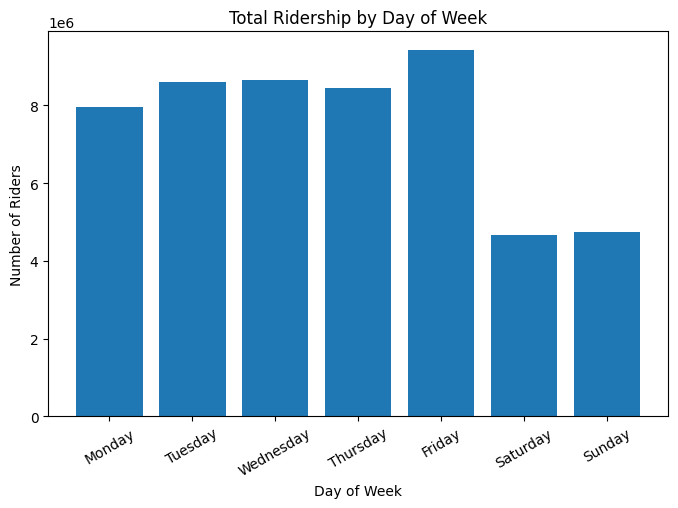

In [8]:
#bar plot of total ridership by day of week 
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_totals = (
    ridership_df.groupby("day_of_week")["riders"]
    .sum()
    .reindex(day_order)
)

plt.figure(figsize=(8, 5))
plt.bar(day_totals.index, day_totals.values)

plt.title("Total Ridership by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Riders")
plt.xticks(rotation=30)
plt.show()

This bar plot shows the number of riders by day of the week. It shows that less people use the bus on th weekend, and the most people are using the bus on Fridays. The y-axis is scaled at 1e^6.

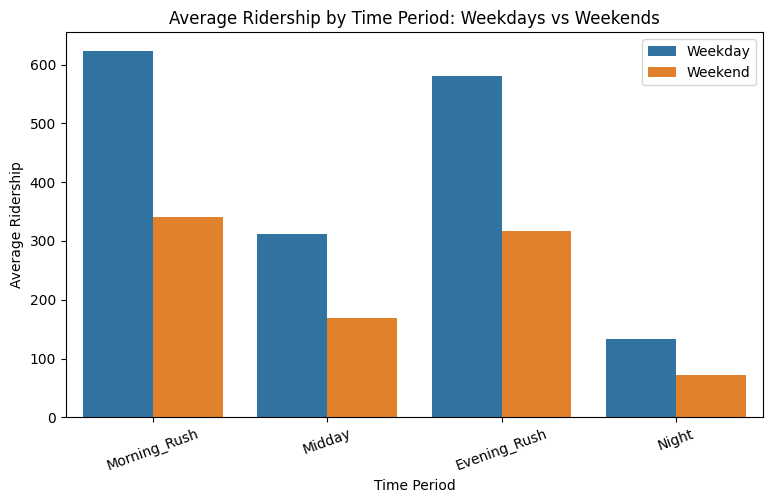

In [9]:
#grouped bar plot 

#(Weekday vs Weekend)
ridership_df["week_part"] = np.where(
    ridership_df["day_of_week"].isin(["Saturday", "Sunday"]),
    "Weekend",
    "Weekday"
)

avg_by_period = (
    ridership_df.groupby(["week_part", "time_period"])["riders"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=avg_by_period,
    x="time_period",
    y="riders",
    hue="week_part",
    order=["Morning_Rush", "Midday", "Evening_Rush", "Night"]
)

plt.title("Average Ridership by Time Period: Weekdays vs Weekends")
plt.xlabel("Time Period")
plt.ylabel("Average Ridership")
plt.xticks(rotation=20)
plt.legend(title="")
plt.show()

This grouped bar plot shows the average ridership split up by time period and weekday versus weekend. This again shows that the morning rush and evening rush have more riders on average, even on the weekends. The pattern for weekend and weekday is very similar when comparing different time periods, with the weekend having less riders on average. 

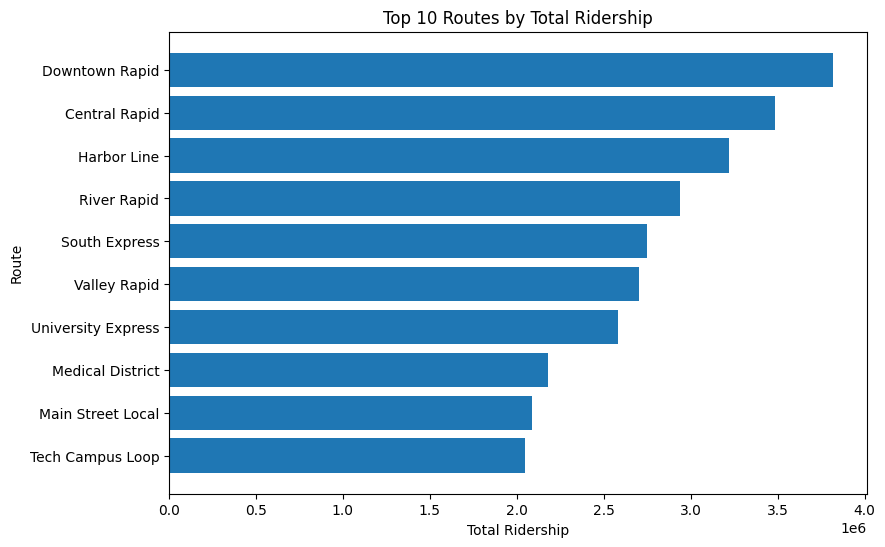

In [10]:
#horizontal bar plot 
top_routes = (
    ridership_df.groupby("route_name")["riders"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(9, 6))
plt.barh(top_routes.index[::-1], top_routes.values[::-1])  # reverse so biggest is at top

plt.title("Top 10 Routes by Total Ridership")
plt.xlabel("Total Ridership")
plt.ylabel("Route")
plt.show()

This horizontal bar plot shows the top 10 routes by total number of riders (again scaled by 1e^6). This shows that the downtown route is the most popular, which makes sense because the most people are likely travelling downtown to and from work and for other activities. 

# Part 3: Relationships and Correlations

Create visualizations exploring relationships between variables:

Create a scatter plot showing the relationship between temperature and ridership. Use color to distinguish between different service areas.

Create a correlation heatmap showing correlations between numeric variables (riders, temperature, precipitation, etc.). Use an appropriate color map.

In your screencast: Discuss what relationships you discovered. Are any patterns surprising?

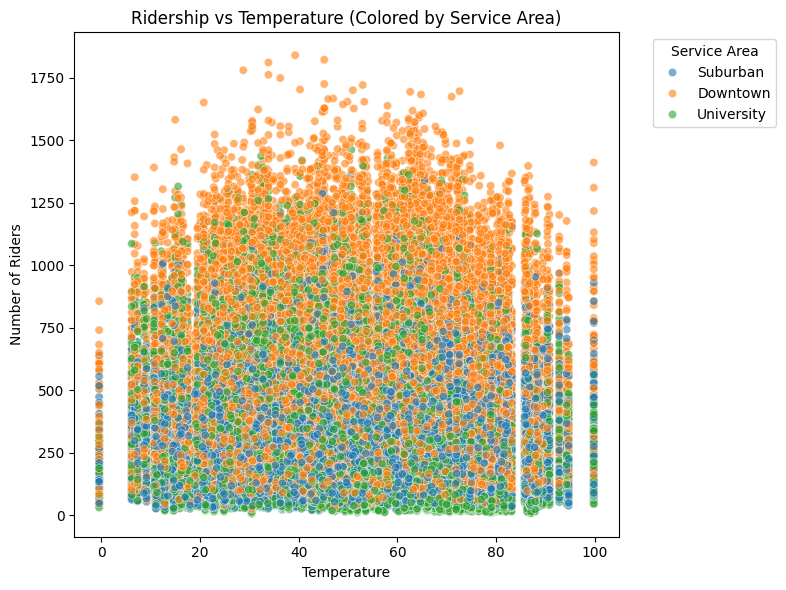

In [20]:
#scatter plot 
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=ridership_df,
    x="temperature_f",
    y="riders",
    hue="service_area",
    alpha=0.6
)

plt.title("Ridership vs Temperature (Colored by Service Area)")
plt.xlabel("Temperature")
plt.ylabel("Number of Riders")
plt.legend(title="Service Area", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

This scatterplot shows the temperature compared to the number of riders, split up by service area. This scatterplot shows that the area with the highest number of riders is the downtown area, which is similar to what we saw in the "Top 10 Routes" bar chart. The distribution is relatively stable, but it shows that the most popular temperature for riders is the more mild temperatures, like around 50 degrees. 

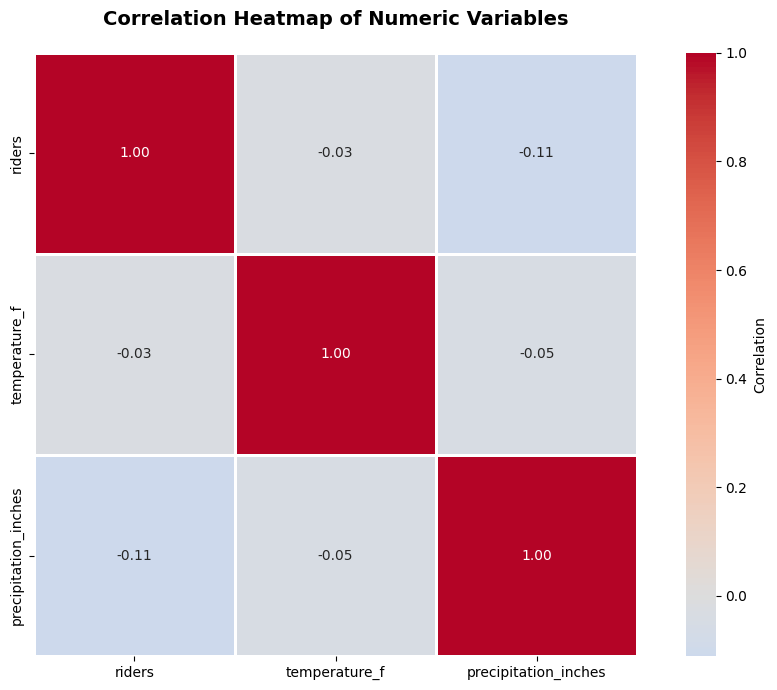

In [17]:
#correlation heatmap 

#first creating the correlation matrix 
numeric_df = ridership_df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, 
            annot=True, 
            center = 0, 
            fmt=".2f", 
            cmap="coolwarm", 
            square=True, 
            linewidths=1,
            cbar_kws={'label': 'Correlation'})

plt.title("Correlation Heatmap of Numeric Variables", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

This correlation heatmap looks at the correlation between temperature, number of riders, and inches of precipitation. We can see that the squares with 1.0 are just where each variable is being compared with itself. There is almost no correlation between temperature and number of riders and temperature and precipitation. There is a slight negative correlation between precipitation inches and number of riders. 

# Part 4: Time Series Visualizations

Create visualizations showing patterns over time:

Create a line plot showing daily total ridership across the entire two-year period. Include proper date formatting on the x-axis.

Create a small multiples (facets) plot (subplots) showing ridership trends for 4-6 different routes over time. Each route should have its own subplot with a shared y-axis for comparison.

Create a heatmap showing average ridership by day of week (rows) and time period (columns). This should reveal weekly and daily patterns.

In your screencast: Explain the temporal patterns you observe. How do trends differ across routes? What seasonal patterns exist?

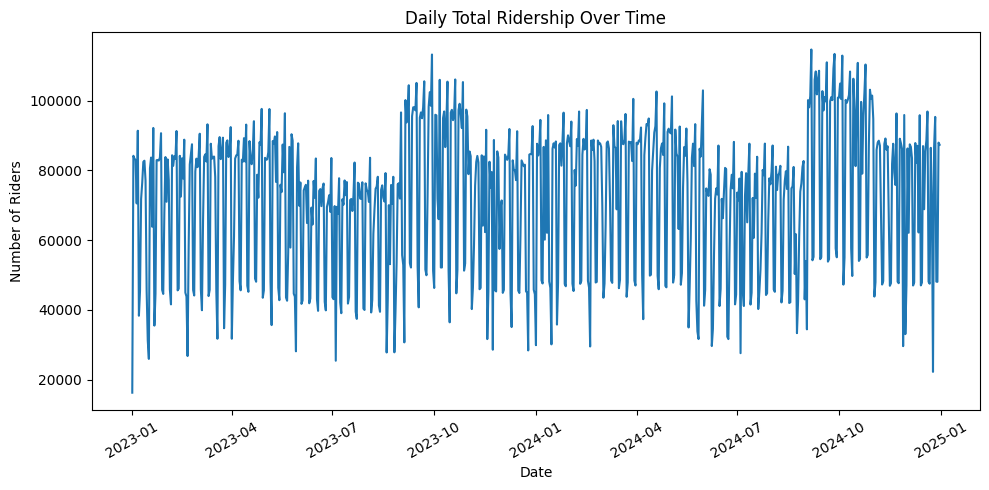

In [13]:
#line plot 
daily_total = (
    ridership_df.groupby("date")["riders"]
    .sum()
    .reset_index()
    .sort_values("date")
)

plt.figure(figsize=(10, 5))
plt.plot(daily_total["date"], daily_total["riders"])

plt.title("Daily Total Ridership Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Riders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

This line plot shows the daily number of riders over time, from January 2023 to January 2025. The numbers stay relatively stable across the 2 year span, with a few spikes around both October 2023 and October 2024. 

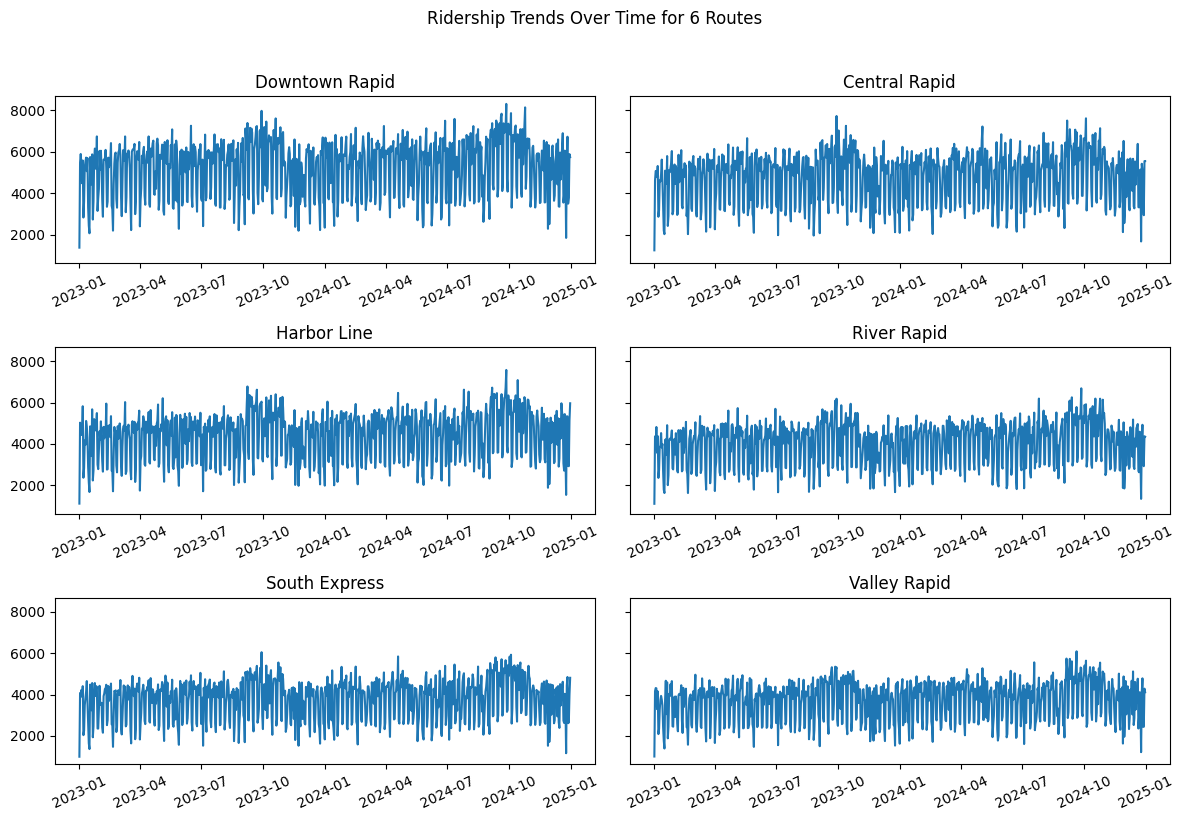

In [14]:
#facets plot

# pick the 6 busiest routes so the plots are meaningful
routes_to_plot = (
    ridership_df.groupby("route_name")["riders"]
    .sum()
    .sort_values(ascending=False)
    .head(6)
    .index
    .tolist()
)

route_daily = (
    ridership_df[ridership_df["route_name"].isin(routes_to_plot)]
    .groupby(["route_name", "date"])["riders"]
    .sum()
    .reset_index()
)

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for i, route_name in enumerate(routes_to_plot):
    route_data = route_daily[route_daily["route_name"] == route_name].sort_values("date")
    axes[i].plot(route_data["date"], route_data["riders"])
    axes[i].set_title(str(route_name))
    axes[i].tick_params(axis="x", rotation=25)

fig.suptitle("Ridership Trends Over Time for 6 Routes", y=1.02)
plt.tight_layout()
plt.show()

This plot is a facets plot showing 6 different line plots of different routes over time and their number of riders. This shows a similar pattern as the others, where the downtown route has a slightly higher average number of riders than the others. 

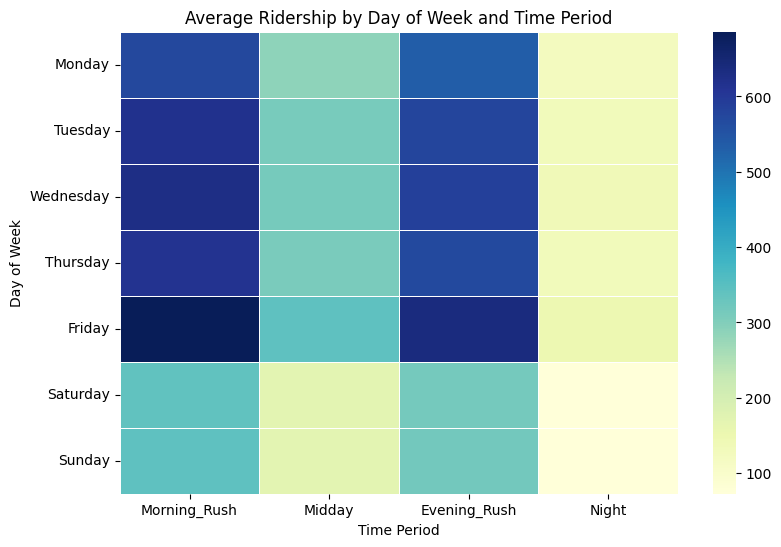

In [15]:
#heatmap 
heat_data = (
    ridership_df.groupby(["day_of_week", "time_period"])["riders"]
    .mean()
    .reset_index()
)

pivot = heat_data.pivot(index="day_of_week", columns="time_period", values="riders")

# Order rows and columns exactly in a logical way
pivot = pivot.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
pivot = pivot[["Morning_Rush", "Midday", "Evening_Rush", "Night"]]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot, cmap="YlGnBu", linewidths=0.5)

plt.title("Average Ridership by Day of Week and Time Period")
plt.xlabel("Time Period")
plt.ylabel("Day of Week")
plt.show()

This heatmap shows the average ridership based on the time of day and the day of the week. It again shows that average riderships is higher during the morning rush and evening rush, and during the weekdays. The weekends have a higher average ridership during those rush times as well, compared to the midday and night during the weekend. Night overall has the lowest average ridership for any day of the week. 

# Part 5: Advanced Composition

Create a comprehensive multi-panel figure that tells a cohesive story about the data:

Use plt.subplots() or Seaborn's FacetGrid to create a figure with at least 4 panels showing complementary visualizations.

The panels should work together to answer a specific question, such as:

"How do weather conditions affect ridership patterns?"
"What makes certain routes more successful than others?"
"How have ridership patterns changed from 2023 to 2024?"
You can use one of those questions or, better still, generate your own.

Apply consistent styling across all panels (colors, fonts, sizing). Include a descriptive overall title.

In your screencast: Walk through your figure panel by panel, explaining how they work together to tell a story about the data.

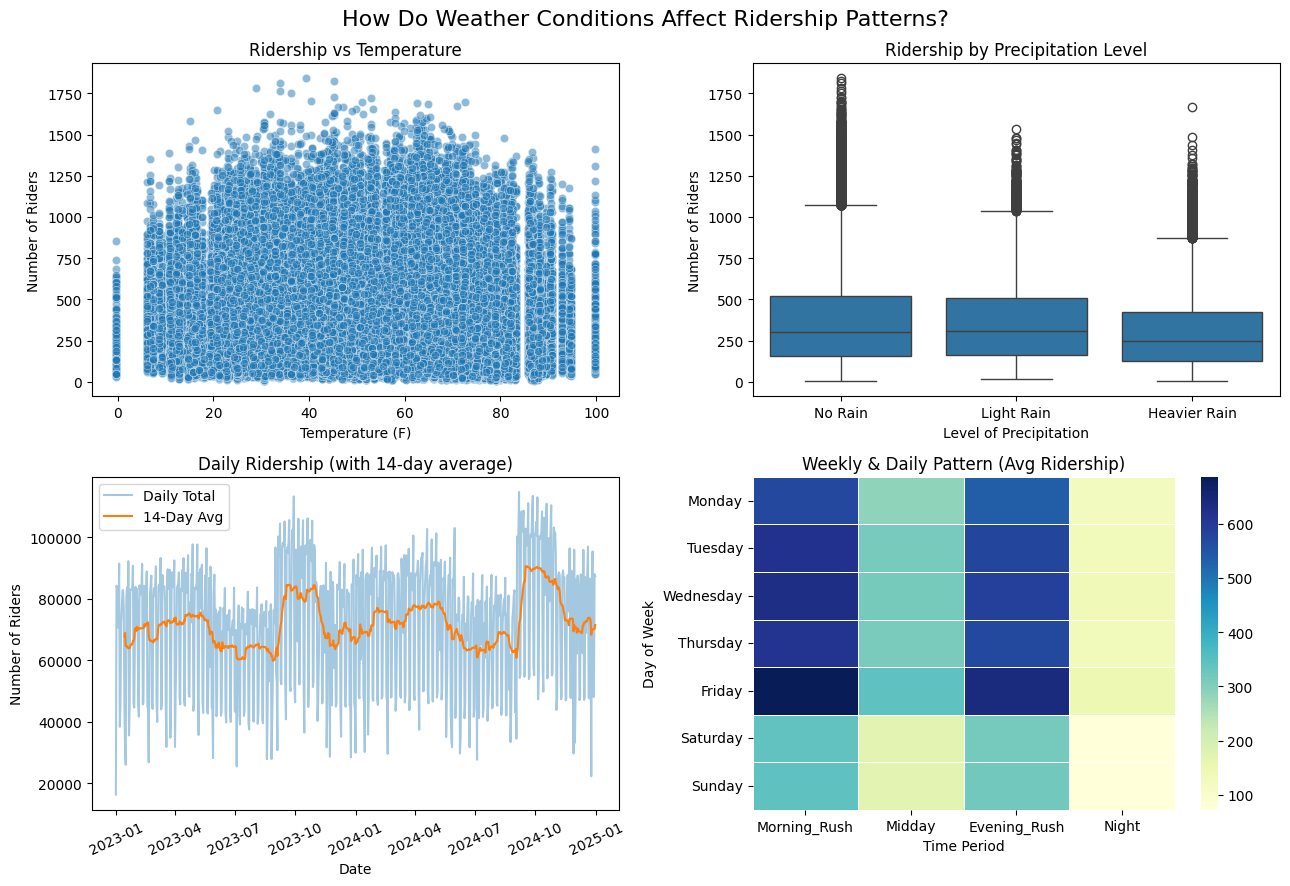

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("How Do Weather Conditions Affect Ridership Patterns?", fontsize=16)

# Panel 1: Scatter (temperature vs ridership)
sns.scatterplot(
    data=ridership_df,
    x="temperature_f",
    y="riders",
    alpha=0.5,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Ridership vs Temperature")
axes[0, 0].set_xlabel("Temperature (F)")
axes[0, 0].set_ylabel("Number of Riders")

# Panel 2: Box plot (ridership by precipitation level)
# Make simple bins so it stays beginner-friendly
ridership_df["precip_level"] = pd.cut(
    ridership_df["precipitation_inches"],
    bins=[-0.01, 0, 0.1, 100],
    labels=["No Rain", "Light Rain", "Heavier Rain"]
)

sns.boxplot(
    data=ridership_df,
    x="precip_level",
    y="riders",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Ridership by Precipitation Level")
axes[0, 1].set_xlabel("Level of Precipitation")
axes[0, 1].set_ylabel("Number of Riders")

# Panel 3: Time series (daily total) with a simple rolling mean
daily_total = (
    ridership_df.groupby("date")["riders"]
    .sum()
    .reset_index()
    .sort_values("date")
)
daily_total["rolling_14"] = daily_total["riders"].rolling(14).mean()

axes[1, 0].plot(daily_total["date"], daily_total["riders"], alpha=0.4, label="Daily Total")
axes[1, 0].plot(daily_total["date"], daily_total["rolling_14"], label="14-Day Avg")
axes[1, 0].set_title("Daily Ridership (with 14-day average)")
axes[1, 0].set_xlabel("Date")
axes[1, 0].set_ylabel("Number of Riders")
axes[1, 0].tick_params(axis="x", rotation=25)
axes[1, 0].legend()

# Panel 4: Heatmap day/time (weekly pattern)
heat_data = (
    ridership_df.groupby(["day_of_week", "time_period"])["riders"]
    .mean()
    .reset_index()
)
pivot = heat_data.pivot(index="day_of_week", columns="time_period", values="riders")
pivot = pivot.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
pivot = pivot[["Morning_Rush", "Midday", "Evening_Rush", "Night"]]

sns.heatmap(pivot, cmap="YlGnBu", linewidths=0.5, ax=axes[1, 1])
axes[1, 1].set_title("Weekly & Daily Pattern (Avg Ridership)")
axes[1, 1].set_xlabel("Time Period")
axes[1, 1].set_ylabel("Day of Week")

plt.tight_layout()
plt.show()

This group of 4 plots aims to answer the question "How Do Weather Conditions Affect Ridership Patterns?". These are the same plots as before-- for example the scatterplot shows the number of riders compared to the temperature, just without the service areas color coded. 
The grouped box plot again shows the precipitation level compared to the number of riders, showing that the averages are similar, but there are more outliers on the upper edge for no rain and light rain. Heaver rain has a smaller and lower distribution by a little bit than the other two. 
The line plot shows the date compared to the number of riders, with an orange line showing the rolling average. You can see the spikes during October in 2023 and 2024, which could be correlated with the winter weather. 
The heatmap shows the day of the week and time period and the average ridership in both. It shows that the most popular times are morning rush and evening rush, even during the weekend. 

All of these graphs together show the mild, calm weather is when the most people are riding, but the weather doesn't have too much of an influence on the number of riders, because people will use public transit no matter what. 